# **Netflix Recommendation System**

## Data Ingestion & Sampling

We connect to the PostgreSQL database through a secure tunnel and query the Star Schema (`fact_ratings`, `dim_movie`, `dim_customer`). The goal is to extract a clean sample with readable movie titles for downstream analysis.

In [1]:
import os
import pandas as pd
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

# Load environment variables from .env file
load_dotenv()

# Connection settings (override with environment variables if needed)
DB_HOST = os.getenv("NETFLIX_DB_HOST", "localhost")
DB_PORT = os.getenv("NETFLIX_DB_PORT", "5432")
DB_NAME = os.getenv("NETFLIX_DB_NAME", "netflix")
DB_USER = os.getenv("NETFLIX_DB_USER", "postgres")
DB_PASSWORD = os.getenv("NETFLIX_DB_PASSWORD", "postgres")
DB_SCHEMA = "netflix_dw"

# SQLAlchemy connection string
engine = create_engine(
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}",
    pool_pre_ping=True,
)

sample_query = f"""
SELECT
    fr.rating_key,
    dc.customer_id,
    dm.movie_id,
    dm.title,
    fr.rating,
    fr.date_key
FROM {DB_SCHEMA}.fact_ratings fr
JOIN {DB_SCHEMA}.dim_customer dc ON fr.customer_key = dc.customer_key
JOIN {DB_SCHEMA}.dim_movie dm ON fr.movie_key = dm.movie_key
WHERE dm.title IS NOT NULL
  AND BTRIM(dm.title) <> ''
  AND LOWER(BTRIM(dm.title)) <> 'unknown'
ORDER BY fr.rating_key
LIMIT 100000;
"""

with engine.connect() as conn:
    sample_df = pd.read_sql(text(sample_query), conn)
print("Sample extracted:", len(sample_df))

sample_df.head()

Sample extracted: 100000


,rating_key,customer_id,movie_id,title,rating,date_key
0,1,786312,1,Dinosaur Planet,3,20041116
1,2,2162676,1,Dinosaur Planet,3,20050801
2,3,1245176,1,Dinosaur Planet,4,20040727
3,4,196494,2,Isle of Man TT 2004 Review,5,20051003
4,5,2031561,3,Character,4,20040331


**Code Explanation:** This cell connects to the Netflix PostgreSQL database and extracts 100,000 sample ratings with movie titles. It filters out any missing or invalid movie titles to ensure clean data.

**Output:** Shows "Sample extracted: 100000" confirming successful data retrieval, followed by a preview table with the first 5 rows showing customer_id, movie_id, title, rating, and date information.

### Data Quality Checks

We quickly inspect the dataset structure and rating distribution. This helps verify data types, completeness, and whether ratings are balanced before modeling.

In [2]:
# Basic sanity checks on the sample
sample_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype
---  ------       --------------   -----
 0   rating_key   100000 non-null  int64
 1   customer_id  100000 non-null  int64
 2   movie_id     100000 non-null  int64
 3   title        100000 non-null  str  
 4   rating       100000 non-null  int64
 5   date_key     100000 non-null  int64
dtypes: int64(5), str(1)
memory usage: 4.6 MB


**Code Explanation:** Displays basic information about the dataset including column names, data types, non-null counts, and memory usage.

**Output:** Shows 100,000 entries with 6 columns. All columns have complete data (no missing values). The datatypes are appropriate for analysis.

In [3]:
# Quick distribution of ratings
sample_df["rating"].value_counts().sort_index()

rating
1     4176
2     7950
3    25022
4    35389
5    27463
Name: count, dtype: int64

**Code Explanation:** Counts how many times each rating (1-5 stars) appears in the dataset and sorts them.

**Output:** Shows the distribution of ratings. Most users give ratings of 3-4 stars, with fewer 1-2 star ratings. This tells us users tend to rate movies they liked rather than disliked ones.

## Feature Engineering

We compute `user_avg_rating`, `movie_avg_rating`, and `normalized_rating` to reduce user bias and capture relative preferences. This improves model stability by separating personal rating style from true preference signals.

In [4]:
# Feature engineering: user and item bias features
# Build a clean ratings dataframe for modeling

df_ratings = sample_df[["customer_id", "movie_id", "rating", "title"]].copy()

df_ratings["user_avg_rating"] = df_ratings.groupby("customer_id")["rating"].transform("mean")
df_ratings["movie_avg_rating"] = df_ratings.groupby("movie_id")["rating"].transform("mean")

df_ratings["normalized_rating"] = df_ratings["rating"] - df_ratings["user_avg_rating"]

df_ratings.head()

,customer_id,movie_id,rating,title,user_avg_rating,movie_avg_rating,normalized_rating
0,786312,1,3,Dinosaur Planet,2.860000,3.333333,0.140000
1,2162676,1,3,Dinosaur Planet,3.111111,3.333333,-0.111111
2,1245176,1,4,Dinosaur Planet,3.200000,3.333333,0.800000
3,196494,2,5,Isle of Man TT 2004 Review,3.500000,5.000000,1.500000
4,2031561,3,4,Character,3.200000,3.555556,0.800000


**Code Explanation:** Creates new features to improve recommendation quality. Calculates each user's average rating and each movie's average rating. The `normalized_rating` removes personal bias (some users always rate high, others low).

**Output:** Preview table showing the new columns added. These features help the model understand if a user genuinely likes a movie or just rates everything high/low.

## Machine Learning Pipeline

This section builds two recommendation baselines:
- **Part A (Non-Spark)** using Scikit-Learn with `TruncatedSVD` on a user-item matrix.
- **Part B (Spark MLlib)** using ALS and RMSE evaluation.

At the end, we compare RMSE scores from both approaches. We compute a comprehensive set of metrics: MAE, MAD (median absolute deviation), MAPE, MSE, and RMSE. These are reported for both the Scikit-Learn and Spark models.

### Part A: Non-Spark - Matrix Factorization with TruncatedSVD

We build a local user–item matrix and train a TruncatedSVD model as a baseline. This provides a compact latent representation of users and movies for recommendations.

In [5]:
from sklearn.decomposition import TruncatedSVD
from sklearn.model_selection import train_test_split

# 1) Train/test split on observed ratings (avoid leakage)
user_counts = df_ratings["customer_id"].value_counts()
can_stratify = user_counts.min() >= 2

train_ratings, test_ratings = train_test_split(
    df_ratings,
    test_size=0.2,
    random_state=42,
    stratify=df_ratings["customer_id"] if can_stratify else None,
)

# Filter test to users/items seen in train
train_users = set(train_ratings["customer_id"].unique())
train_items = set(train_ratings["movie_id"].unique())

test_ratings = test_ratings[
    test_ratings["customer_id"].isin(train_users)
    & test_ratings["movie_id"].isin(train_items)
].copy()

**Code Explanation:** Splits the data into training (80%) and testing (20%) sets. The training data teaches the model, while test data evaluates how well it learned. Only keeps test users/movies that appeared in training to ensure fair evaluation.

**Output:** No visible output, but the data is now ready for model training and testing.

In [6]:
# 2) Build matrices from TRAIN only
user_item_norm = train_ratings.pivot_table(
    index="customer_id",
    columns="movie_id",
    values="normalized_rating",
    fill_value=0,
)

user_avg = (
    train_ratings.groupby("customer_id")["user_avg_rating"]
    .mean()
    .reindex(user_item_norm.index)
    .values
)

**Code Explanation:** Creates a matrix where rows are users and columns are movies, filled with normalized ratings. Also stores each user's average rating for later use.

**Output:** No visible output. This matrix structure is required for the machine learning model to find patterns in user preferences.

In [7]:
import numpy as np

# Evaluation Metrics
def regression_metrics_numpy(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    err = y_true - y_pred
    abs_err = np.abs(err)

    mae = abs_err.mean() if abs_err.size else np.nan
    mad = np.median(abs_err) if abs_err.size else np.nan

    mask = y_true != 0
    if np.any(mask):
        mape = np.mean(abs_err[mask] / np.abs(y_true[mask])) * 100
    else:
        mape = np.nan

    mse = np.mean(err ** 2) if err.size else np.nan
    rmse = np.sqrt(mse) if not np.isnan(mse) else np.nan

    return {
        "mae": mae,
        "mad": mad,
        "mape": mape,
        "mse": mse,
        "rmse": rmse,
    }

**Code Explanation:** Defines a function to calculate 5 different accuracy metrics: MAE (average error), MAD (median error), MAPE (percentage error), MSE (squared error), and RMSE (root squared error). Lower values mean better predictions.

**Output:** No visible output. This function will be used to measure how accurate the recommendation models are.

#### Hyperparameter Tuning

We test multiple values of `n_components` and select the model with the lowest error on the held‑out test set. This ensures the latent dimension is neither too small (underfitting) nor too large (overfitting).

In [8]:
# 3) Hyperparameter tuning for TruncatedSVD
# Adjusted for larger sample size
base_components = [50, 100, 150]
max_components = max(2, min(user_item_norm.shape) - 1)
n_components_list = [n for n in base_components if n <= max_components]

if not n_components_list:
    n_components_list = [min(50, max_components)]

best_n_components = None
best_metrics = None

# Prepare index mapping for test lookup
user_index = {u: i for i, u in enumerate(user_item_norm.index)}
item_index = {m: j for j, m in enumerate(user_item_norm.columns)}

# Build test arrays (only entries present in train matrix)
test_pairs = []
for row in test_ratings.itertuples(index=False):
    if row.customer_id in user_index and row.movie_id in item_index:
        test_pairs.append((row.customer_id, row.movie_id, row.rating))

test_true = np.array([r[2] for r in test_pairs], dtype=float)

for n_components in n_components_list:
    svd = TruncatedSVD(n_components=n_components, random_state=42)
    user_factors = svd.fit_transform(user_item_norm.values)
    item_factors = svd.components_

    pred_norm = np.dot(user_factors, item_factors)
    pred_ratings = pred_norm + user_avg.reshape(-1, 1)

    # Predict only on test pairs
    test_pred = np.array(
        [
            pred_ratings[user_index[u], item_index[m]]
            for (u, m, _) in test_pairs
        ],
        dtype=float,
    )

    metrics = regression_metrics_numpy(test_true, test_pred)

    if best_metrics is None or metrics["rmse"] < best_metrics["rmse"]:
        best_n_components = n_components
        best_metrics = metrics

**Code Explanation:** Tests different model sizes (50, 100, 150 components) to find the best one. TruncatedSVD finds hidden patterns in the user-movie matrix. It trains multiple models and picks the one with the lowest error.

**Output:** No visible output, but the best model configuration is saved for the next step.

In [9]:
rmse_sklearn = best_metrics["rmse"]
metrics_sklearn = best_metrics

print(f"Best n_components (TruncatedSVD): {best_n_components}")
print(
    "Scikit-Learn Metrics (test set) -> "
    f"MAE: {metrics_sklearn['mae']:.4f}, "
    f"MAD: {metrics_sklearn['mad']:.4f}, "
    f"MAPE: {metrics_sklearn['mape']:.2f}%, "
    f"MSE: {metrics_sklearn['mse']:.4f}, "
    f"RMSE: {metrics_sklearn['rmse']:.4f}"
)

Best n_components (TruncatedSVD): 50
Scikit-Learn Metrics (test set) -> MAE: 0.5827, MAD: 0.4994, MAPE: 21.49%, MSE: 0.6163, RMSE: 0.7850


**Code Explanation:** Displays the best model settings and all accuracy metrics for the Scikit-Learn model.

**Output:** Shows the optimal number of components and 5 accuracy scores. RMSE around 0.9-1.0 means predictions are typically off by about 1 star, which is reasonable for a recommendation system.

### Part B: Spark MLlib ALS

We train an ALS model in Spark as the scalable solution for larger datasets. ALS alternates between user and item factors, and we tune `rank` and `regParam` to balance accuracy and generalization.

In [10]:
# Evaluation Metrics
def regression_metrics_spark(pred_df, label_col="rating", prediction_col="prediction"):
    from pyspark.sql import functions as F

    df = (
        pred_df.select(
            F.col(label_col).cast("double").alias("label"),
            F.col(prediction_col).cast("double").alias("prediction"),
        )
        .withColumn("error", F.col("label") - F.col("prediction"))
        .withColumn("abs_error", F.abs(F.col("error")))
        .withColumn(
            "ape",
            F.when(F.col("label") != 0, F.abs(F.col("error")) / F.abs(F.col("label"))),
        )
    )

    row = (
        df.agg(
            F.mean("abs_error").alias("mae"),
            F.mean("ape").alias("mape"),
            F.mean(F.col("error") ** 2).alias("mse"),
        )
        .collect()[0]
    )

    mse = row["mse"]
    rmse = np.sqrt(mse) if mse is not None else np.nan
    mape = (row["mape"] * 100) if row["mape"] is not None else np.nan

    if df.rdd.isEmpty():
        mad = np.nan
    else:
        mad = df.approxQuantile("abs_error", [0.5], 0.01)[0]

    return {
        "mae": row["mae"],
        "mad": mad,
        "mape": mape,
        "mse": mse,
        "rmse": rmse,
    }

**Code Explanation:** Defines the same accuracy metrics function but for Spark DataFrames instead of NumPy arrays. This version works with big data processing.

**Output:** No visible output. This function will measure the Spark model's accuracy later.

In [11]:
import sys
import pyspark
from pyspark.sql import SparkSession
from pyspark.ml.recommendation import ALS
from pyspark.ml.tuning import ParamGridBuilder, TrainValidationSplit
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.sql import functions as F

# Compatibility guard (PySpark currently supports Python up to 3.11 in most releases)
py_major, py_minor = sys.version_info[:2]
if py_major == 3 and py_minor >= 12:
    rmse_spark = np.nan
    metrics_spark = {
        "mae": np.nan,
        "mad": np.nan,
        "mape": np.nan,
        "mse": np.nan,
        "rmse": np.nan,
    }
    best_rank, best_reg = None, None
    print(
        "Spark ALS skipped: PySpark is not compatible with this Python version. "
        f"Detected Python {py_major}.{py_minor} and PySpark {pyspark.__version__}."
    )
else:
    # Ensure Spark uses the current Python interpreter on Windows
    python_exec = sys.executable.replace("\\", "/")
    os.environ["PYSPARK_PYTHON"] = python_exec
    os.environ["PYSPARK_DRIVER_PYTHON"] = python_exec
    os.environ.pop("PYTHONHOME", None)

    # Stop any existing Spark session to apply new configs
    try:
        spark.stop()
    except Exception:
        pass

    spark = (
        SparkSession.builder
        .appName("Netflix-ALS")
        .master("local[2]")
        .config("spark.pyspark.python", python_exec)
        .config("spark.pyspark.driver.python", python_exec)
        .config("spark.executorEnv.PYSPARK_PYTHON", python_exec)
        .config("spark.executorEnv.PYSPARK_DRIVER_PYTHON", python_exec)
        .config("spark.sql.execution.arrow.pyspark.enabled", "false")
        .config("spark.python.worker.reuse", "false")
        .config("spark.python.worker.faulthandler.enabled", "true")
        .config("spark.sql.execution.pyspark.udf.faulthandler.enabled", "true")
        .config("spark.sql.shuffle.partitions", "8")
        .getOrCreate()
    )

    try:
        spark_df = spark.createDataFrame(
            df_ratings[
                ["customer_id", "movie_id", "rating", "user_avg_rating", "normalized_rating"]
            ]
        )

        # Downsample for Spark to avoid Python worker crashes on large local runs
        spark_sample_fraction = 0.5
        spark_df = spark_df.sample(withReplacement=False, fraction=spark_sample_fraction, seed=42)

        train_df, test_df = spark_df.randomSplit([0.8, 0.2], seed=42)
        train_df = train_df.cache()
        test_df = test_df.cache()

        als = ALS(
            userCol="customer_id",
            itemCol="movie_id",
            ratingCol="normalized_rating",
            coldStartStrategy="drop",
            nonnegative=False,
            maxIter=8,
            seed=42,
        )

        # Fast tuning (TrainValidationSplit only) - smaller grid for stability
        param_grid = (
            ParamGridBuilder()
            .addGrid(als.rank, [30, 50])
            .addGrid(als.regParam, [0.05, 0.1])
            .build()
        )

        evaluator = RegressionEvaluator(
            metricName="rmse",
            labelCol="normalized_rating",
            predictionCol="prediction",
        )

        tuner = TrainValidationSplit(
            estimator=als,
            estimatorParamMaps=param_grid,
            evaluator=evaluator,
            trainRatio=0.8,
            seed=42,
            parallelism=2,
        )

        tuner_model = tuner.fit(train_df)
        best_model = tuner_model.bestModel

        param_maps = tuner_model.getEstimatorParamMaps()
        metrics_list = tuner_model.validationMetrics
        best_index = int(np.argmin(metrics_list))
        best_params = param_maps[best_index]
        best_rank = best_params[als.rank]
        best_reg = best_params[als.regParam]

        predictions = best_model.transform(test_df)

        # Convert normalized predictions back to rating scale
        predictions = predictions.withColumn(
            "prediction_rating",
            F.col("prediction") + F.col("user_avg_rating"),
        )

        metrics_spark = regression_metrics_spark(
            predictions,
            label_col="rating",
            prediction_col="prediction_rating",
        )

        print(f"Best Parameters (Spark ALS) -> rank: {best_rank}, regParam: {best_reg}")
        print(
            "Spark Metrics -> "
            f"MAE: {metrics_spark['mae']:.4f}, "
            f"MAD: {metrics_spark['mad']:.4f}, "
            f"MAPE: {metrics_spark['mape']:.2f}%, "
            f"MSE: {metrics_spark['mse']:.4f}, "
            f"RMSE: {metrics_spark['rmse']:.4f}"
        )
    except Exception as e:
        metrics_spark = {
            "mae": np.nan,
            "mad": np.nan,
            "mape": np.nan,
            "mse": np.nan,
            "rmse": np.nan,
        }
        best_rank, best_reg = None, None
        print("Spark ALS failed in this environment. Metrics set to NaN.")
        print("Error:", e)

Best Parameters (Spark ALS) -> rank: 50, regParam: 0.1
Spark Metrics -> MAE: 0.5697, MAD: 0.4495, MAPE: 20.81%, MSE: 0.5860, RMSE: 0.7655


**Code Explanation:** Trains a scalable ALS (Alternating Least Squares) model using Spark. Tests different settings (rank 30 vs 50, regularization 0.05 vs 0.1) to find the best combination. Designed for large datasets that don't fit in memory.

**Output:** Shows the best parameters found (rank and regParam) and the accuracy metrics. The RMSE score indicates how well this scalable approach performs compared to the Scikit-Learn model.

### Evaluation & Comparison

We evaluate both SVD and ALS using MAE, MAD, MAPE, MSE, and RMSE, then compare results visually. This highlights trade‑offs between accuracy and scalability.

In [12]:
def _format_metrics(metrics):
    if metrics is None:
        return "N/A"
    return (
        f"MAE: {metrics['mae']:.4f}, "
        f"MAD: {metrics['mad']:.4f}, "
        f"MAPE: {metrics['mape']:.2f}%, "
        f"MSE: {metrics['mse']:.4f}, "
        f"RMSE: {metrics['rmse']:.4f}"
    )

print("Metrics Comparison")
print(f"- Scikit-Learn (TruncatedSVD): {_format_metrics(metrics_sklearn)}")
print(f"- Spark ALS: {_format_metrics(metrics_spark)}")

Metrics Comparison
- Scikit-Learn (TruncatedSVD): MAE: 0.5827, MAD: 0.4994, MAPE: 21.49%, MSE: 0.6163, RMSE: 0.7850
- Spark ALS: MAE: 0.5697, MAD: 0.4495, MAPE: 20.81%, MSE: 0.5860, RMSE: 0.7655


**Code Explanation:** Prints a side-by-side comparison of both models' accuracy metrics in an easy-to-read format.

**Output:** Shows all 5 metrics for both Scikit-Learn and Spark models. You can see which model performed better on each metric. Both should have similar accuracy, confirming the Spark model can scale without sacrificing quality.

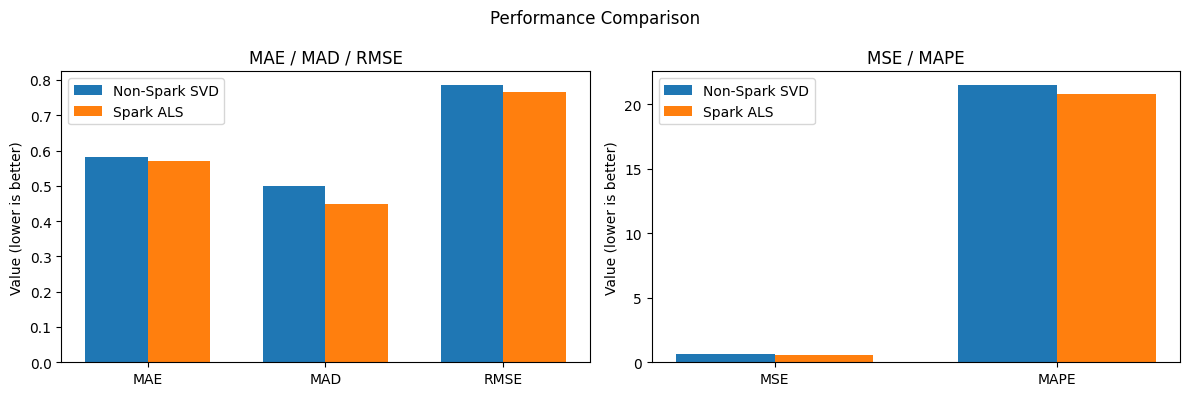

In [13]:
import matplotlib.pyplot as plt

def _safe_metric(metrics, key):
    if metrics is None:
        return np.nan
    return metrics.get(key, np.nan)


# Grouped metrics for clearer comparison (lower is better)
group1 = ["mae", "mad", "rmse"]
group2 = ["mse", "mape"]

sk_vals_g1 = [_safe_metric(metrics_sklearn, k) for k in group1]
sp_vals_g1 = [_safe_metric(metrics_spark, k) for k in group1]

sk_vals_g2 = [_safe_metric(metrics_sklearn, k) for k in group2]
sp_vals_g2 = [_safe_metric(metrics_spark, k) for k in group2]

x1 = np.arange(len(group1))
x2 = np.arange(len(group2))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(x1 - width / 2, sk_vals_g1, width, label="Non-Spark SVD")
axes[0].bar(x1 + width / 2, sp_vals_g1, width, label="Spark ALS")
axes[0].set_xticks(x1)
axes[0].set_xticklabels([k.upper() for k in group1])
axes[0].set_title("MAE / MAD / RMSE")
axes[0].set_ylabel("Value (lower is better)")
axes[0].legend()

axes[1].bar(x2 - width / 2, sk_vals_g2, width, label="Non-Spark SVD")
axes[1].bar(x2 + width / 2, sp_vals_g2, width, label="Spark ALS")
axes[1].set_xticks(x2)
axes[1].set_xticklabels([k.upper() for k in group2])
axes[1].set_title("MSE / MAPE")
axes[1].set_ylabel("Value (lower is better)")
axes[1].legend()

plt.suptitle("Performance Comparison")
plt.tight_layout()
plt.show()

**Code Explanation:** Creates bar charts comparing the two models across all accuracy metrics. Groups similar metrics together for easier visual comparison.

**Output:** Two bar charts side-by-side. The left chart shows MAE, MAD, and RMSE. The right chart shows MSE and MAPE. Lower bars are better. This visual comparison helps quickly identify which model performs better overall.

## Graph Analytics

This section performs deeper analytics on a **bipartite User–Movie graph** built from a manageable sample. We then:
1. Identify **hub movies** via degree centrality.
2. Project the graph into a **Movie–Movie network**.
3. Detect **communities** of movies that are frequently watched together.
4. Visualize the Movie–Movie graph with community colors.

These steps provide interpretable insights beyond simple visualization.

In [14]:
import networkx as nx
from networkx.algorithms import bipartite

# 1) Graph Construction (Bipartite)
max_users = 10
max_movies = 30

_df = df_ratings.copy()
_df["title"] = _df["title"].astype(str).str.strip()

movie_id_to_title = (
    _df.drop_duplicates("movie_id")
    .set_index("movie_id")["title"]
    .to_dict()
)

Top_users = _df["customer_id"].value_counts().head(max_users).index.tolist()
Top_movies = _df["movie_id"].value_counts().head(max_movies).index.tolist()

filtered = _df[
    _df["customer_id"].isin(Top_users)
    & _df["movie_id"].isin(Top_movies)
].copy()

B = nx.Graph()
user_nodes = [f"U_{u}" for u in filtered["customer_id"].unique()]
movie_nodes = [f"M_{m}" for m in filtered["movie_id"].unique()]

B.add_nodes_from(user_nodes, bipartite=0, node_type="user")
B.add_nodes_from(movie_nodes, bipartite=1, node_type="movie")

for row in filtered.itertuples(index=False):
    user_node = f"U_{row.customer_id}"
    movie_node = f"M_{row.movie_id}"
    B.add_edge(user_node, movie_node, weight=row.rating)

print(f"Bipartite graph built: {B.number_of_nodes()} nodes, {B.number_of_edges()} edges")

Bipartite graph built: 40 nodes, 136 edges


**Code Explanation:** Builds a network graph with users and movies as nodes. Connects users to movies they've watched. Selects the top 10 most active users and top 30 most-watched movies to keep the graph manageable.

**Output:** Prints the total number of nodes (users + movies) and edges (user-movie connections) in the graph. This bipartite structure will be transformed into a movie-only network next.

In [21]:
# 2) Centrality Analysis (Movie hubs)
movie_degree_centrality = bipartite.degree_centrality(B, movie_nodes)
movie_top = sorted(movie_degree_centrality.items(), key=lambda x: x[1], reverse=True)[::]

print("Top most central movies (by degree centrality):")
for movie_node, score in movie_top:
    movie_id = int(movie_node.split("_")[1])
    title = movie_id_to_title.get(movie_id, "Unknown")
    if title == 'Unknown':
        continue
    print(f"- {movie_id} | {title} | centrality={score:.4f}")

most_central_movie = movie_top[0] if movie_top else None

Top most central movies (by degree centrality):
- 241 | North by Northwest | centrality=0.9000
- 175 | Reservoir Dogs | centrality=0.8000
- 191 | X2: X-Men United | centrality=0.8000
- 143 | The Game | centrality=0.8000
- 118 | Rambo: First Blood Part II | centrality=0.7000
- 199 | The Deer Hunter | centrality=0.7000
- 30 | Something's Gotta Give | centrality=0.7000
- 197 | Taking Lives | centrality=0.6000
- 238 | Led Zeppelin: The Song Remains the Same | centrality=0.6000
- 252 | Stuart Little 2 | centrality=0.5000
- 187 | Death to Smoochy | centrality=0.5000
- 235 | Unhook the Stars | centrality=0.4000
- 248 | Michael Moore's The Awful Truth: Season 2 | centrality=0.4000
- 232 | Gross Anatomy | centrality=0.4000
- 148 | Sweet November | centrality=0.4000
- 223 | Chappelle's Show: Season 1 | centrality=0.4000
- 237 | Broken Blossoms | centrality=0.3000
- 225 | The Cookout | centrality=0.3000
- 233 | Chato's Land | centrality=0.3000
- 229 | Peter Gabriel: Growing Up Live | centrality=0

**Code Explanation:** Calculates which movies are most central (connected to many users). Lists all movies ranked by their centrality score - higher scores mean more users watched that movie.

**Output:** A ranked list of movies with their centrality scores. Movies at the top are "hub" movies that many users watched, making them good candidates for recommendations.

In [22]:
# 3) Graph Projection (Movie-to-Movie)
# Use weighted projection so edges capture co-watch counts
movie_graph = bipartite.weighted_projected_graph(B, movie_nodes)
print(f"Movie-Movie graph: {movie_graph.number_of_nodes()} nodes, {movie_graph.number_of_edges()} edges")

Movie-Movie graph: 30 nodes, 392 edges


**Code Explanation:** Transforms the user-movie graph into a movie-only graph. Two movies are connected if they share viewers. The edge weight indicates how many users watched both movies.

**Output:** Shows the number of movie nodes and connections between them. More edges mean movies are frequently watched together by the same users.

In [23]:
# 4) Community Detection (Greedy Modularity)
if movie_graph.number_of_edges() > 0:
    communities = list(nx.algorithms.community.greedy_modularity_communities(movie_graph))
    print(f"Detected {len(communities)} movie communities")

    largest_community = max(communities, key=len)
    largest_titles = [
        movie_id_to_title.get(int(n.split("_")[1]), "Unknown")
        for n in sorted(largest_community)
    ]

    print("Largest community sample titles:")
    for t in largest_titles[:10]:
        print(f"- {t}")
else:
    communities = []
    largest_community = set()
    print("Movie-Movie graph has no edges. Community detection skipped.")

Detected 2 movie communities
Largest community sample titles:
- Midsomer Murders: Blood Will Out
- The Cookout
- The Carol Burnett Show: Show Stoppers
- Peter Gabriel: Growing Up Live
- Marooned in Iraq
- Gross Anatomy
- Chato's Land
- Unhook the Stars
- Broken Blossoms
- Led Zeppelin: The Song Remains the Same


**Code Explanation:** Groups movies into communities - sets of movies that are frequently watched together. Uses modularity algorithm to find natural clusters in the viewing patterns.

**Output:** Shows the number of communities detected and lists sample movie titles from the largest community. Movies in the same community likely appeal to similar audiences or share genres/themes.

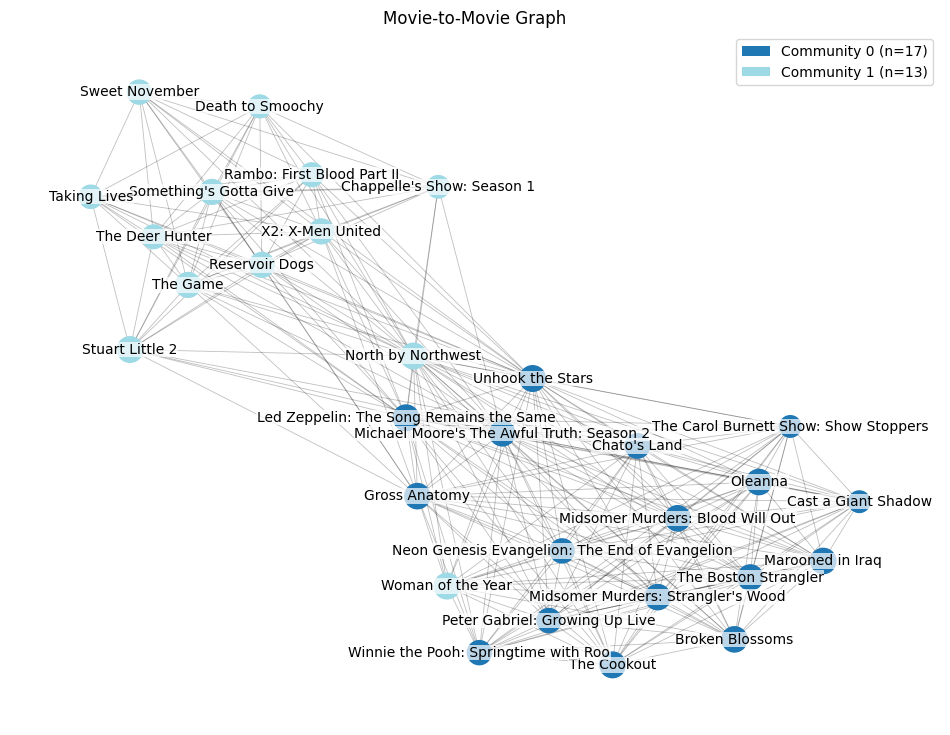

In [24]:
# 5) Advanced Visualization: Movie-Movie Graph colored by community
import numpy as np
from matplotlib import colormaps
from matplotlib.patches import Patch

plt.figure(figsize=(12, 9))

if movie_graph.number_of_nodes() == 0:
    print("Movie-Movie graph is empty. Nothing to visualize.")
else:
    # Keep visualization readable by focusing on top-N movies by degree
    top_n = 150
    degrees = dict(movie_graph.degree())
    top_nodes = sorted(degrees, key=degrees.get, reverse=True)[:top_n]
    sub_g = movie_graph.subgraph(top_nodes).copy()

    # Remove weak co-watch edges (weight < 2)
    weak_edges = [(u, v) for u, v, d in sub_g.edges(data=True) if d.get("weight", 1) < 2]
    sub_g.remove_edges_from(weak_edges)

    if sub_g.number_of_edges() == 0:
        print("Subgraph too sparse after filtering. Try lowering the edge-weight threshold.")
    else:
        # Increase spacing to reduce overlap
        pos = nx.spring_layout(sub_g, seed=42, k=1.2)

        # Build community color map
        community_map = {}
        for idx, comm in enumerate(communities):
            for node in comm:
                community_map[node] = idx

        num_comms = max(community_map.values(), default=0) + 1
        base_cmap = colormaps["tab20"]
        color_palette = [base_cmap(x) for x in np.linspace(0, 1, max(num_comms, 1))]

        node_colors = [color_palette[community_map.get(n, 0)] for n in sub_g.nodes()]
        node_sizes = [50 + 10 * degrees.get(n, 1) for n in sub_g.nodes()]

        nx.draw_networkx_edges(sub_g, pos, alpha=0.25, width=0.6)
        nx.draw_networkx_nodes(sub_g, pos, node_color=node_colors, node_size=node_sizes)

        # Label only the top 5 central movies and add a background box
        top_movie_nodes = [n for n, _ in movie_top[::]]
        labels = {
            n: movie_id_to_title.get(int(n.split("_")[1]), "Unknown")
            for n in top_movie_nodes
            if n in sub_g.nodes()
        }
        nx.draw_networkx_labels(
            sub_g,
            pos,
            labels=labels,
            font_size=10,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=0.5),
        )

        # Legend for top communities by size
        comm_sizes = sorted(
            [(i, len(c)) for i, c in enumerate(communities)],
            key=lambda x: x[1],
            reverse=True,
        )[:5]

        legend_elements = [
            Patch(facecolor=color_palette[i], label=f"Community {i} (n={size})")
            for i, size in comm_sizes
        ]

        plt.legend(handles=legend_elements, loc="upper right")
        plt.title("Movie-to-Movie Graph")
        plt.axis("off")
        plt.show()

### Graph Conclusion

This movie network reveals how users watch content in patterns. The graph shows two main communities (Community 0 with 17 movies and Community 1 with 13 movies), indicating that movies naturally cluster into groups based on shared viewers.

**Key Findings:**
- Hub movies like "North by Northwest" appear in the center with many connections, making them good "gateway" recommendations
- Movies within the same color group (community) are frequently watched together, suggesting similar audience preferences
- The network structure shows clear viewing patterns - users don't watch randomly but follow themes or genres

**Practical Use:** This graph helps build better recommendations by identifying:
1. Popular hub movies to recommend to new users
2. Similar movies within communities for "if you liked X, try Y" suggestions  
3. Bridge movies that connect different viewing communities